In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity, mean_squared_error
print("Библиотеки загружены")

Библиотеки загружены


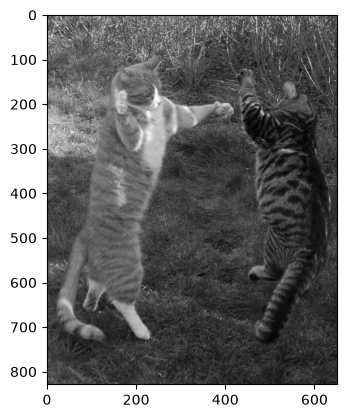

In [4]:
image_gray = cv2.imread('img_2_lab.jpg', cv2.IMREAD_GRAYSCALE)
plt.imshow(image_gray, cmap='gray')

Text(0.5, 1.0, 'Постоянный шум')

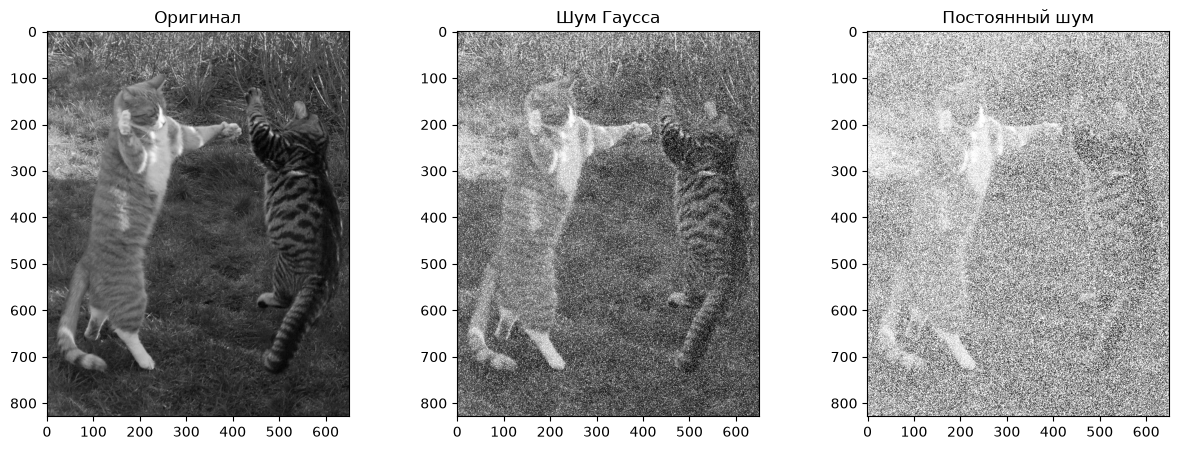

In [5]:
# Зашумить изображение при помощи шума гаусса, постоянного шума.
# Шум Гаусса
mean = 0
stddev = 100
noise_gauss = np.zeros(image_gray.shape, np.uint8)
cv2.randn(noise_gauss, mean, stddev)

image_noise_gauss = cv2.add(image_gray, noise_gauss)

# Постоянный шум
low = -50
high = 50
uniform_noise = np.random.uniform(low, high, image_gray.shape)

image_noise_uniform = cv2.add(image_gray, uniform_noise.astype(np.uint8))

# Вывод изобр.
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image_gray, cmap='gray')
plt.title('Оригинал')

plt.subplot(1, 3, 2)
plt.imshow(image_noise_gauss, cmap='gray')
plt.title('Шум Гаусса')

plt.subplot(1, 3, 3)
plt.imshow(image_noise_uniform, cmap='gray')
plt.title('Постоянный шум')

Text(0.5, 1.0, 'NLM(h=20)')

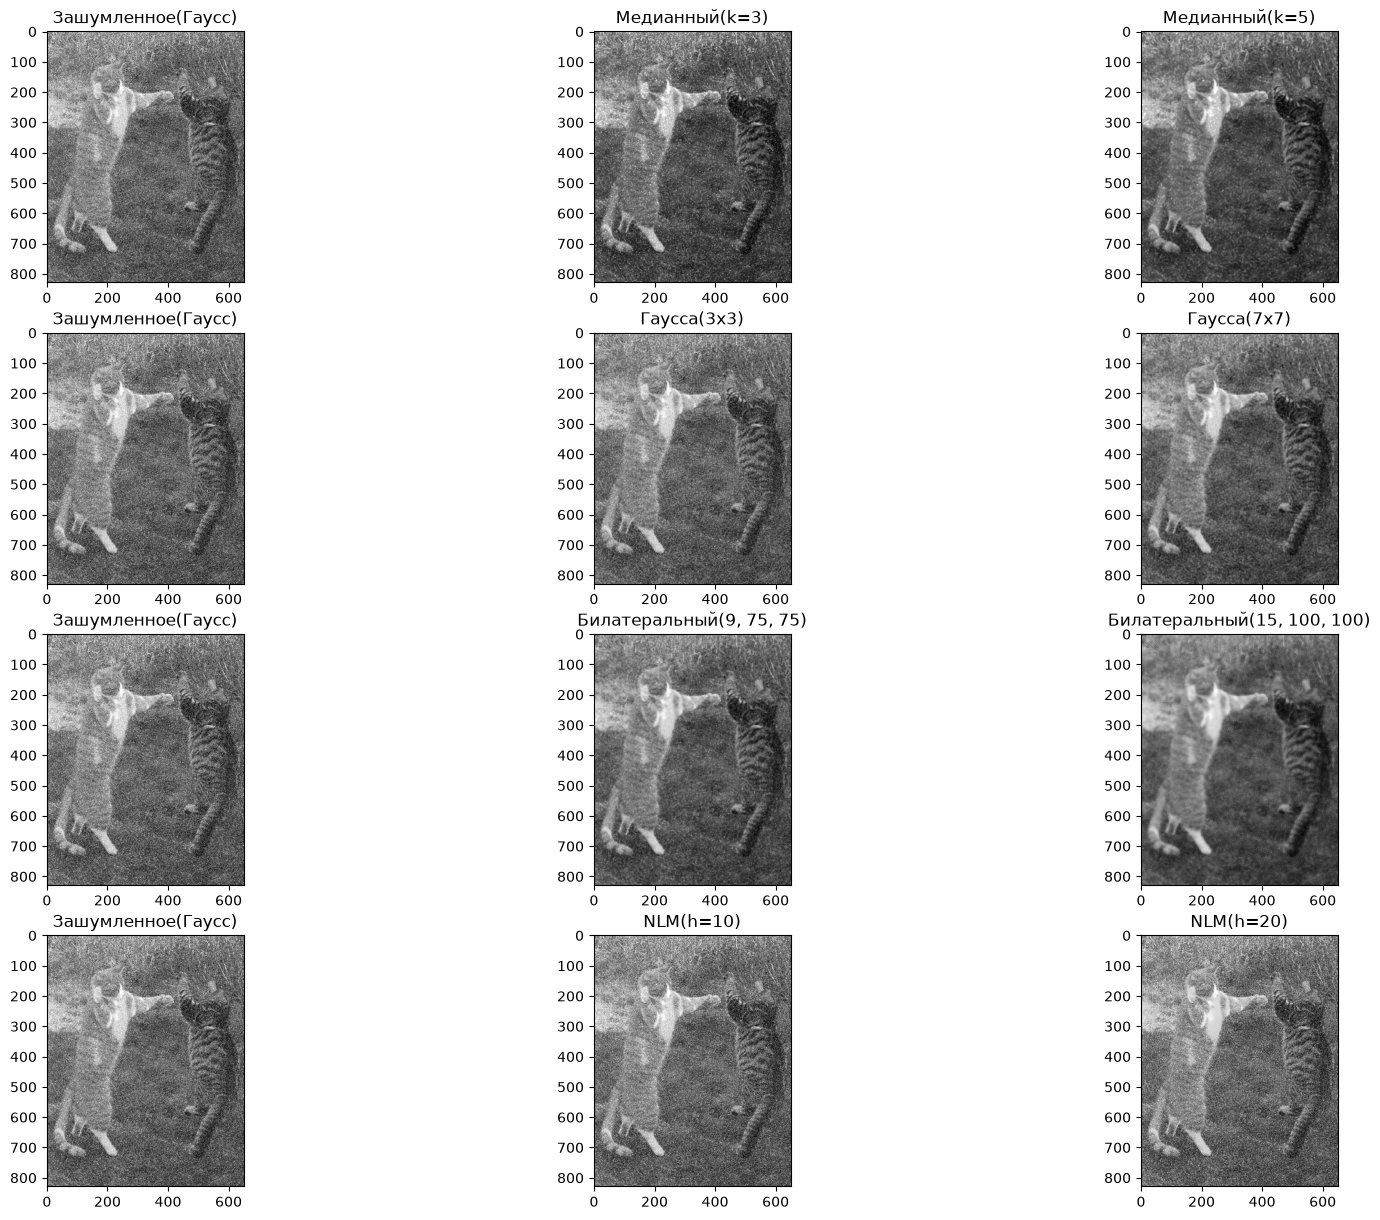

In [9]:
# Тестирование фильтров с различными параметрами на шуме Гаусса
plt.figure(figsize=(20, 15))

# Медианный фильтр
img_med_3 = cv2.medianBlur(image_noise_gauss, 3)
img_med_5 = cv2.medianBlur(image_noise_gauss, 5)

plt.subplot(4, 3, 1)
plt.imshow(image_noise_gauss, cmap='gray')
plt.title('Зашумленное(Гаусс)')
plt.subplot(4, 3, 2)
plt.imshow(img_med_3, cmap='gray')
plt.title('Медианный(k=3)')
plt.subplot(4, 3, 3)
plt.imshow(img_med_5, cmap='gray')
plt.title('Медианный(k=5)')

# Фильтр Гаусса
img_gauss_3 = cv2.GaussianBlur(image_noise_gauss, (3, 3), 0)
img_gauss_7 = cv2.GaussianBlur(image_noise_gauss, (7, 7), 0)

plt.subplot(4, 3, 4)
plt.imshow(image_noise_gauss, cmap='gray')
plt.title('Зашумленное(Гаусс)')
plt.subplot(4, 3, 5)
plt.imshow(img_gauss_3, cmap='gray')
plt.title('Гаусса(3x3)')
plt.subplot(4, 3, 6)
plt.imshow(img_gauss_7, cmap='gray')
plt.title('Гаусса(7x7)')

# Билатеральный фильтр
img_bilat_9 = cv2.bilateralFilter(image_noise_gauss, 9, 75, 75)
img_bilat_15 = cv2.bilateralFilter(image_noise_gauss, 15, 100, 100)

plt.subplot(4, 3, 7)
plt.imshow(image_noise_gauss, cmap='gray')
plt.title('Зашумленное(Гаусс)')
plt.subplot(4, 3, 8)
plt.imshow(img_bilat_9, cmap='gray')
plt.title('Билатеральный(9, 75, 75)')
plt.subplot(4, 3, 9)
plt.imshow(img_bilat_15, cmap='gray')
plt.title('Билатеральный(15, 100, 100)')

# Фильтр нелокальных средних(NLM)
img_nlm_10 = cv2.fastNlMeansDenoising(image_noise_gauss, h=10)
img_nlm_20 = cv2.fastNlMeansDenoising(image_noise_gauss, h=20)

plt.subplot(4, 3, 10)
plt.imshow(image_noise_gauss, cmap='gray')
plt.title('Зашумленное(Гаусс)')
plt.subplot(4, 3, 11)
plt.imshow(img_nlm_10, cmap='gray')
plt.title('NLM(h=10)')
plt.subplot(4, 3, 12)
plt.imshow(img_nlm_20, cmap='gray')
plt.title('NLM(h=20)')

In [7]:
print("Результаты для шума Гаусса")

print(f"Медианный (3):  MSE = {mean_squared_error(image_gray, img_med_3):.2f}, SSIM = {structural_similarity(image_gray, img_med_3, full=True)[0]:.4f}")
print(f"Медианный (5):  MSE = {mean_squared_error(image_gray, img_med_5):.2f}, SSIM = {structural_similarity(image_gray, img_med_5, full=True)[0]:.4f}")

print(f"Гаусса (3x3):   MSE = {mean_squared_error(image_gray, img_gauss_3):.2f}, SSIM = {structural_similarity(image_gray, img_gauss_3, full=True)[0]:.4f}")
print(f"Гаусса (7x7):   MSE = {mean_squared_error(image_gray, img_gauss_7):.2f}, SSIM = {structural_similarity(image_gray, img_gauss_7, full=True)[0]:.4f}")

print(f"Билатер. (9):   MSE = {mean_squared_error(image_gray, img_bilat_9):.2f}, SSIM = {structural_similarity(image_gray, img_bilat_9, full=True)[0]:.4f}")
print(f"Билатер. (15):  MSE = {mean_squared_error(image_gray, img_bilat_15):.2f}, SSIM = {structural_similarity(image_gray, img_bilat_15, full=True)[0]:.4f}")

print(f"NLM (h=10):     MSE = {mean_squared_error(image_gray, img_nlm_10):.2f}, SSIM = {structural_similarity(image_gray, img_nlm_10, full=True)[0]:.4f}")
print(f"NLM (h=20):     MSE = {mean_squared_error(image_gray, img_nlm_20):.2f}, SSIM = {structural_similarity(image_gray, img_nlm_20, full=True)[0]:.4f}")

Результаты для шума Гаусса
Медианный (3):  MSE = 989.20, SSIM = 0.3617
Медианный (5):  MSE = 615.91, SSIM = 0.4413
Гаусса (3x3):   MSE = 1871.39, SSIM = 0.3732
Гаусса (7x7):   MSE = 1668.20, SSIM = 0.4634
Билатер. (9):   MSE = 1782.43, SSIM = 0.2699
Билатер. (15):  MSE = 1489.61, SSIM = 0.3197
NLM (h=10):     MSE = 4189.89, SSIM = 0.1444
NLM (h=20):     MSE = 4167.43, SSIM = 0.1513


Text(0.5, 1.0, 'NLM(h=20)')

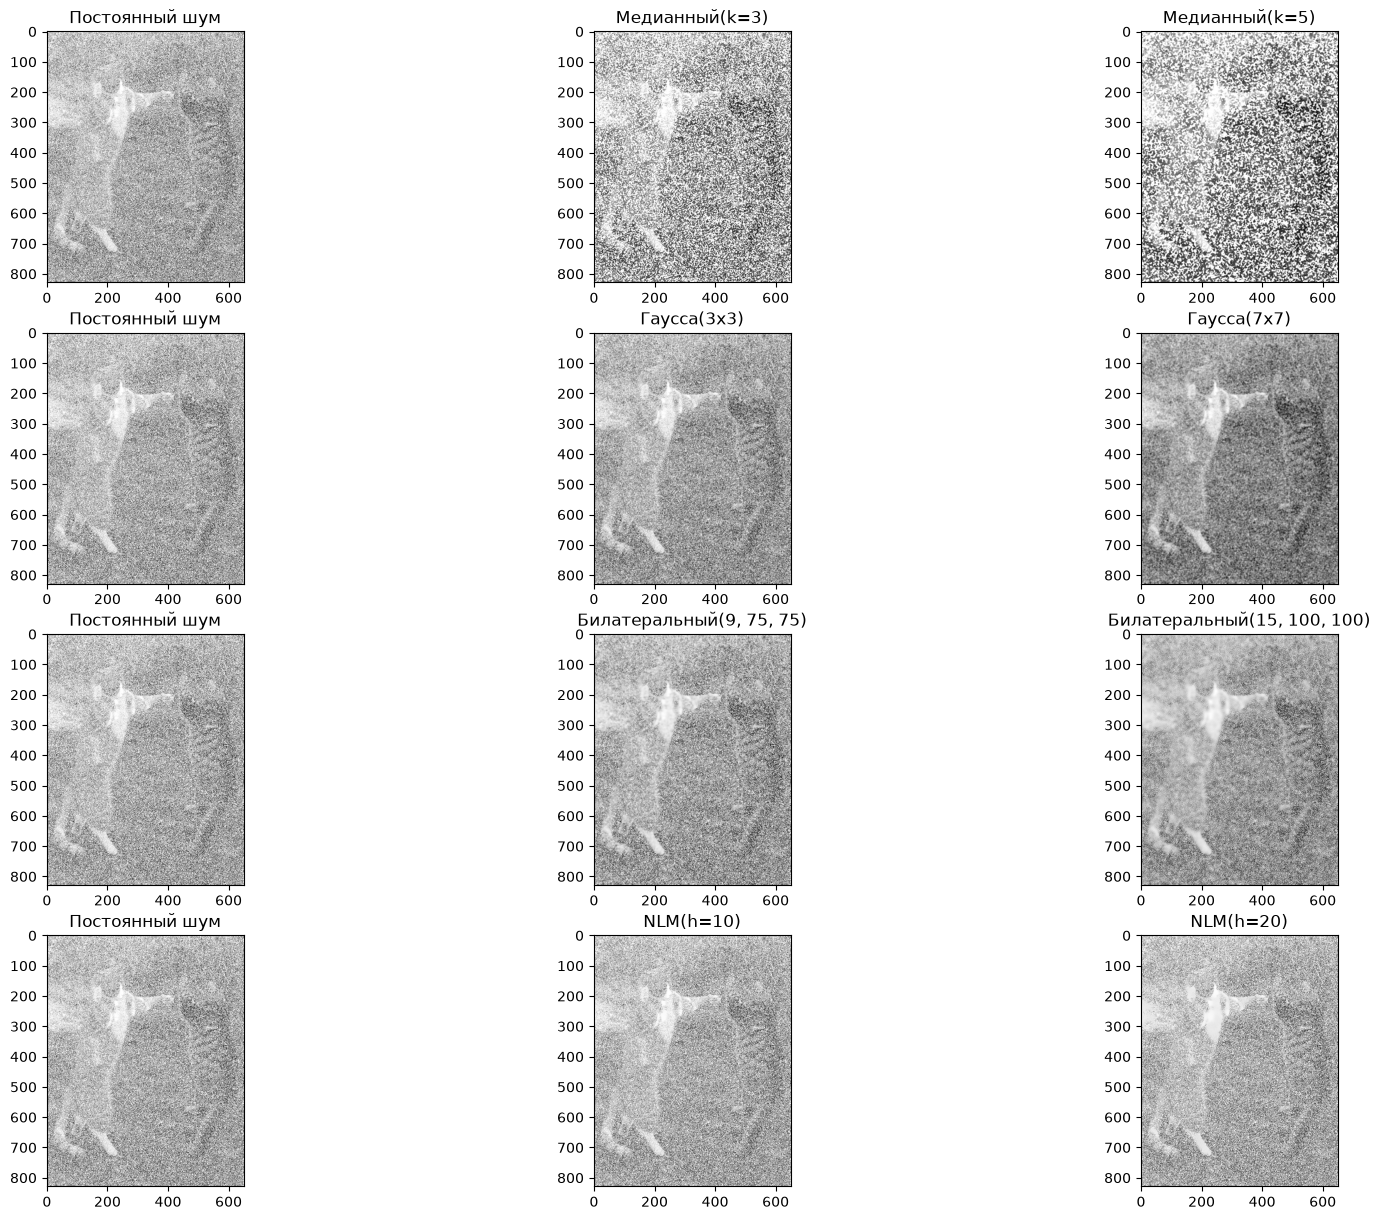

In [8]:
# Тестирование всех фильтров на постоянном шуме

plt.figure(figsize=(20, 15))

# Медианный фильтр
uni_med_3 = cv2.medianBlur(image_noise_uniform, 3)
uni_med_5 = cv2.medianBlur(image_noise_uniform, 5)

plt.subplot(4, 3, 1)
plt.imshow(image_noise_uniform, cmap='gray')
plt.title('Постоянный шум')
plt.subplot(4, 3, 2)
plt.imshow(uni_med_3, cmap='gray')
plt.title('Медианный(k=3)')
plt.subplot(4, 3, 3)
plt.imshow(uni_med_5, cmap='gray')
plt.title('Медианный(k=5)')

# Фильтр Гаусса
uni_gauss_3 = cv2.GaussianBlur(image_noise_uniform, (3, 3), 0)
uni_gauss_7 = cv2.GaussianBlur(image_noise_uniform, (7, 7), 0)

plt.subplot(4, 3, 4)
plt.imshow(image_noise_uniform, cmap='gray')
plt.title('Постоянный шум')
plt.subplot(4, 3, 5)
plt.imshow(uni_gauss_3, cmap='gray')
plt.title('Гаусса(3x3)')
plt.subplot(4, 3, 6)
plt.imshow(uni_gauss_7, cmap='gray')
plt.title('Гаусса(7x7)')

# Билатеральный фильтр
uni_bilat_9 = cv2.bilateralFilter(image_noise_uniform, 9, 75, 75)
uni_bilat_15 = cv2.bilateralFilter(image_noise_uniform, 15, 100, 100)

plt.subplot(4, 3, 7)
plt.imshow(image_noise_uniform, cmap='gray')
plt.title('Постоянный шум')
plt.subplot(4, 3, 8)
plt.imshow(uni_bilat_9, cmap='gray')
plt.title('Билатеральный(9, 75, 75)')
plt.subplot(4, 3, 9)
plt.imshow(uni_bilat_15, cmap='gray')
plt.title('Билатеральный(15, 100, 100)')

# NLM
uni_nlm_10 = cv2.fastNlMeansDenoising(image_noise_uniform, h=10)
uni_nlm_20 = cv2.fastNlMeansDenoising(image_noise_uniform, h=20)

plt.subplot(4, 3, 10)
plt.imshow(image_noise_uniform, cmap='gray')
plt.title('Постоянный шум')
plt.subplot(4, 3, 11)
plt.imshow(uni_nlm_10, cmap='gray')
plt.title('NLM(h=10)')
plt.subplot(4, 3, 12)
plt.imshow(uni_nlm_20, cmap='gray')
plt.title('NLM(h=20)')

In [10]:
print("Результаты для постоянного шума")

print(f"Медианный (3):  MSE = {mean_squared_error(image_gray, uni_med_3):.2f}, SSIM = {structural_similarity(image_gray, uni_med_3, full=True)[0]:.4f}")
print(f"Медианный (5):  MSE = {mean_squared_error(image_gray, uni_med_5):.2f}, SSIM = {structural_similarity(image_gray, uni_med_5, full=True)[0]:.4f}")

print(f"Гаусса (3x3):   MSE = {mean_squared_error(image_gray, uni_gauss_3):.2f}, SSIM = {structural_similarity(image_gray, uni_gauss_3, full=True)[0]:.4f}")
print(f"Гаусса (7x7):   MSE = {mean_squared_error(image_gray, uni_gauss_7):.2f}, SSIM = {structural_similarity(image_gray, uni_gauss_7, full=True)[0]:.4f}")

print(f"Билатер. (9):   MSE = {mean_squared_error(image_gray, uni_bilat_9):.2f}, SSIM = {structural_similarity(image_gray, uni_bilat_9, full=True)[0]:.4f}")
print(f"Билатер. (15):  MSE = {mean_squared_error(image_gray, uni_bilat_15):.2f}, SSIM = {structural_similarity(image_gray, uni_bilat_15, full=True)[0]:.4f}")

print(f"NLM (h=10):     MSE = {mean_squared_error(image_gray, uni_nlm_10):.2f}, SSIM = {structural_similarity(image_gray, uni_nlm_10, full=True)[0]:.4f}")
print(f"NLM (h=20):     MSE = {mean_squared_error(image_gray, uni_nlm_20):.2f}, SSIM = {structural_similarity(image_gray, uni_nlm_20, full=True)[0]:.4f}")

Результаты для постоянного шума
Медианный (3):  MSE = 16464.75, SSIM = 0.0498
Медианный (5):  MSE = 16303.80, SSIM = 0.0506
Гаусса (3x3):   MSE = 11147.51, SSIM = 0.1530
Гаусса (7x7):   MSE = 10564.26, SSIM = 0.2301
Билатер. (9):   MSE = 14603.64, SSIM = 0.0798
Билатер. (15):  MSE = 12751.77, SSIM = 0.0983
NLM (h=10):     MSE = 16537.29, SSIM = 0.0508
NLM (h=20):     MSE = 16523.26, SSIM = 0.0581


In [ ]:
# Для Гаусса: 
# Лучший по MSE:медианный(k=5)=615.91
# Лучший по SSIM:Гаусса(7x7)=0.4634
# При шуме Гаусса наиболее хорошие результаты показали медианный фильтр и фильтр Гаусса
# Для постоянного шума:
# Лучший по MSE:Гаусса(7x7)=10564,26
# Лучший по SSIM:Гаусса(7x7)=0,2301
# При постоянном шуме наилучший результат показал фильтр Гаусса